# Picking retenido y cycle-skipping

**Nivel 3 — Crítica de investigación**  
**Prerrequisitos:** niveles 1–2 y fundamentos de inversión; 35 min.

## Objetivos

Siga la evidencia desde el contrato fuente hasta el resultado. Declare unidades y supuestos, reproduzca el cálculo e identifique qué inferencia no respalda la evidencia.

## Preparación

Usa módulos y registros versionados desde la raíz descubierta; no descarga ni modifica fuentes. Instale versiones exactas: `pip install numpy==2.2.6 matplotlib==3.10.8`

## Datos

Hay trazas STEAD retenidas y recibos FWI; distinga conteos medidos, FWI sintético, etiquetas humanas y activos web.

## Método

PhaseNet produce probabilidades P/S/ruido por muestra a partir de ondas de tres componentes; umbral, máximos y separación convierten probabilidades en tiempos. El benchmark retenido del producto selecciona 6.000 trazas STEAD reales (5.926 válidas, 74 rechazadas), compara picks de analistas a ±0,5 s e informa F1 y falsos picks en ruido válido por fase. No son etiquetas de verdad geológica. Compare condición nominal y estrés, y revise manifiesto: 24 trazas reales, 100 Hz, 60 s, conteos normalizados, `browser_parity_verified=false`, probabilidades no calibradas. F1 nativo no prueba paridad del navegador. Esa afirmación exige mismas trazas, paridad de probabilidades y picks, tolerancias explícitas. Conserve fallos y declare cambio de dominio e incertidumbre de etiquetas.

A 100 muestras/s, Nyquist es 50 Hz; respuesta instrumental y preprocesamiento determinan ancho de banda útil. Rayos tomográficos dependen de velocidad actual; FWI usa fase y amplitud completas. Mantenga trazas/disparos retenidos fuera del ajuste. Menor residuo de entrenamiento puede coexistir con peor WRMS retenido o estructura en ciclo equivocado.

## Estado del arte

El estado del arte no es una tabla de posiciones: separe formulación publicada, implementación del producto y evidencia versionada. Una afirmación de avance requiere dominios retenidos independientes, incertidumbre calibrada y réplica.

## Resultados

Lea ejes físicos y unidades; distinga ajuste, error contra verdad sintética y acuerdo con etiquetas humanas. El recálculo debe concordar con el recibo. Un modelo graficado no demuestra unicidad, transferencia a campo ni resolución.

### Diagnostic 1

Inspeccione el recibo y procedencia del caso.

In [1]:
from pathlib import Path
from importlib.metadata import version
print("Runtime versions:", {name: version(name) for name in ['numpy', 'matplotlib']})
import numpy as np
root=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/"data").is_dir() and (p/"data-pipeline").is_dir())
# Inspect held-out benchmark, actual browser manifest, and native scores under nominal/stress conditions.
import json
from pathlib import Path
b=json.loads((root/"data/derived/phase/stead-heldout-benchmark.json").read_text(encoding="utf-8")); manifest=json.loads((root/"data/derived/phase/browser-assets/stead/manifest.json").read_text(encoding="utf-8"))
print("selected/valid/rejected",b["selected"],b["valid"],b["qc_rejected"],"reference",b["reference"],"parity",manifest["browser_parity_verified"],"calibrated",manifest["model"]["probabilities_calibrated"])
for c in ("nominal","shift_plus_800","drop_Z"): print(c,{m:[round(b["metrics"][c][m][p]["f1_at_0p5s"],3) for p in ("P","S")] for m in ("M08","M13")})

Runtime versions: {'numpy': '2.2.6', 'matplotlib': '3.10.8'}
selected/valid/rejected 6000 5926 74 reference STEAD manual P/S picks, not geological truth parity False calibrated False
nominal {'M08': [0.083, 0.025], 'M13': [0.981, 0.955]}
shift_plus_800 {'M08': [0.051, 0.011], 'M13': [0.981, 0.956]}
drop_Z {'M08': [0.056, 0.023], 'M13': [0.903, 0.935]}


### Diagnostic 2

Calcule la comparación y grafíquela con unidades físicas.

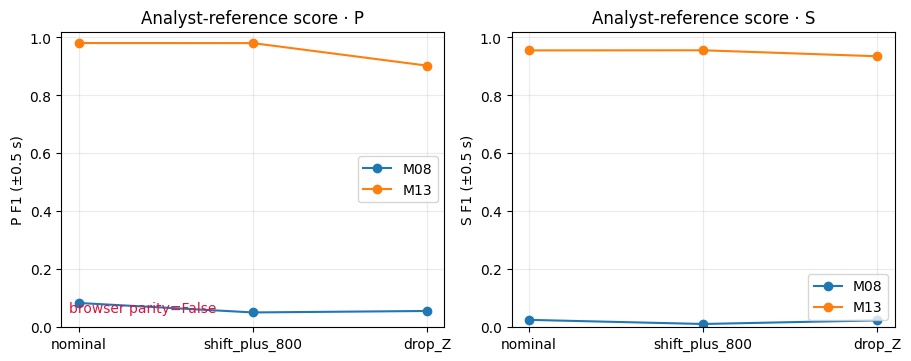

Native F1 does not establish browser parity.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
# Plot native held-out F1 by phase across stress, with browser parity shown independently.
import matplotlib.pyplot as plt
conds=["nominal","shift_plus_800","drop_Z"]; fig,ax=plt.subplots(1,2,figsize=(9,3.5),constrained_layout=True)
for a,p in zip(ax,["P","S"]):
 for m in ("M08","M13"): a.plot(conds,[b["metrics"][c][m][p]["f1_at_0p5s"] for c in conds],"o-",label=m)
 a.set(ylim=(0,1.02),ylabel=p+" F1 (±0.5 s)",title="Analyst-reference score · "+p); a.grid(alpha=.25); a.legend()
ax[0].text(.02,.05,"browser parity="+str(manifest["browser_parity_verified"]),transform=ax[0].transAxes,color="crimson"); plt.show(); print("Native F1 does not establish browser parity.")

## Resumen

La conclusión depende de geometría, adquisición, ruido, partición, parametrización y derechos de fuente. Conserve negativos y nombre la observación o control siguiente.

## Referencias

- [https://docs.obspy.org/packages/autogen/obspy.core.stream.Stream.html](https://docs.obspy.org/packages/autogen/obspy.core.stream.Stream.html)
- [https://www.pygimli.org/_examples_auto/2_seismics/plot_04_koenigsee/](https://www.pygimli.org/_examples_auto/2_seismics/plot_04_koenigsee/)
- [https://www.devitoproject.org/examples/seismic/tutorials/03_fwi.html](https://www.devitoproject.org/examples/seismic/tutorials/03_fwi.html)